# The Dead Neuron Problem in Neural Networks

**What you will learn in this notebook**

1. Why a ReLU neuron can get stuck outputting zero *forever* ("dies"), shown at the gradient level
2. How to **detect** dead neurons in a PyTorch model (forward hooks)
3. The three classic **causes**: too-high learning rate, bad initialisation / biases, unscaled inputs
4. The standard **fixes**: lower LR, Kaiming init, Leaky ReLU / ELU / GELU, BatchNorm
5. How to run a fair side-by-side comparison with the same PyTorch train loop

We reuse the basic PyTorch training-loop pattern: `Dataset` -> `DataLoader` -> `nn.Module` -> loss + optimizer -> `train_one_epoch` / `evaluate`, with a few extra tools bolted on to watch neurons die.

In [1]:
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", device)

torch 2.15.0+cu132 | device: cpu


## 1. The idea: ReLU has a flat side

$$\text{ReLU}(z) = \max(0, z) \qquad \frac{d\,\text{ReLU}}{dz} = \begin{cases}1 & z > 0\\ 0 & z \le 0\end{cases}$$

For a neuron $a = \text{ReLU}(w^\top x + b)$, backprop gives

$$\frac{\partial L}{\partial w} = \frac{\partial L}{\partial a}\cdot \mathbb{1}[z>0]\cdot x$$

If $z \le 0$ for **every** input in the dataset, the indicator is 0 everywhere, so the gradient on $w$ and $b$ is **exactly zero**. The optimizer has no signal to move the neuron, so it stays dead for the rest of training (plain SGD, no momentum or weight decay changes it).

Let's look at it.

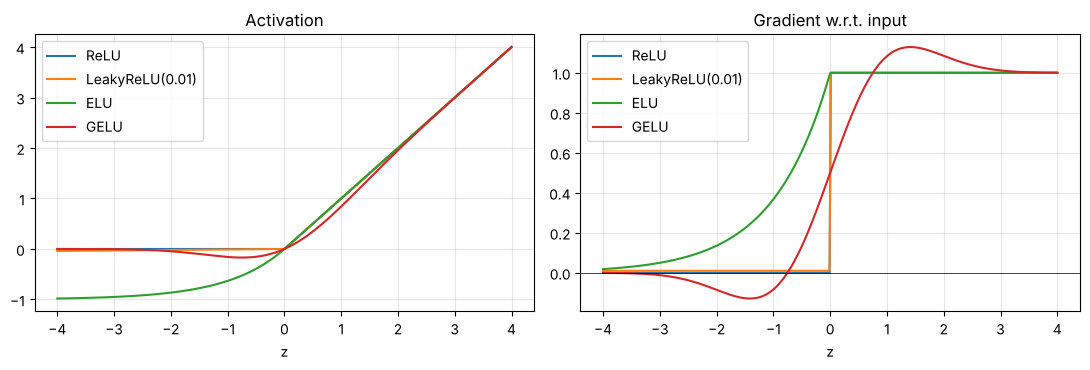

In [2]:
z = torch.linspace(-4, 4, 400, requires_grad=True)

acts = {
    "ReLU": torch.relu,
    "LeakyReLU(0.01)": lambda t: nn.functional.leaky_relu(t, 0.01),
    "ELU": nn.functional.elu,
    "GELU": nn.functional.gelu,
}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, f in acts.items():
    y = f(z)
    g, = torch.autograd.grad(y.sum(), z)
    axes[0].plot(z.detach(), y.detach(), label=name)
    axes[1].plot(z.detach(), g, label=name)
axes[0].set_title("Activation"); axes[1].set_title("Gradient w.r.t. input")
axes[1].axhline(0, color="k", lw=0.5)
for a in axes:
    a.set_xlabel("z"); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

Notice the ReLU gradient is **exactly 0** for $z<0$. The others keep a small non-zero gradient there, which is what lets a neuron recover.

### Gradient-level proof on a single neuron

In [3]:
# One neuron whose pre-activation is negative for every input
x = torch.randn(256, 2)
neuron = nn.Linear(2, 1)
with torch.no_grad():
    neuron.weight.copy_(torch.tensor([[0.5, 0.5]]))
    neuron.bias.fill_(-100.0)          # pushes z far below zero for all x

for name, act in [("ReLU", nn.ReLU()), ("LeakyReLU", nn.LeakyReLU(0.01))]:
    neuron.zero_grad()
    out = act(neuron(x)).mean()
    out.backward()
    print(f"{name:10s} | output={out.item():+.4f} | "
          f"|grad W|={neuron.weight.grad.abs().sum().item():.6f} | "
          f"|grad b|={neuron.bias.grad.abs().sum().item():.6f}")

ReLU       | output=+0.0000 | |grad W|=0.000000 | |grad b|=0.000000
LeakyReLU  | output=-0.9997 | |grad W|=0.001677 | |grad b|=0.010000


ReLU gives **zero gradient** -> the neuron can never learn its way back. Leaky ReLU still passes a (tiny) gradient.

## 2. A toy problem: two spirals

A non-linear 2-D classification task: small enough to train in seconds, hard enough that capacity (i.e. *live* neurons) matters.

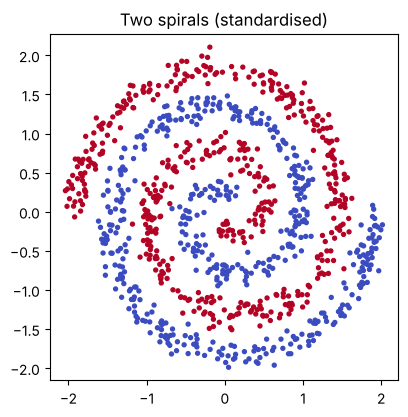

train: (800, 2) test: (200, 2)


In [4]:
def make_spirals(n_per_class=500, noise=0.15, turns=2.0, seed=0):
    rng = np.random.RandomState(seed)
    t = np.sqrt(rng.rand(n_per_class)) * turns * 2 * np.pi
    xs, ys = [], []
    for label, phase in enumerate([0.0, np.pi]):
        r = t / (turns * 2 * np.pi)
        x1 = r * np.cos(t + phase) + noise * rng.randn(n_per_class) * 0.3
        x2 = r * np.sin(t + phase) + noise * rng.randn(n_per_class) * 0.3
        xs.append(np.stack([x1, x2], 1)); ys.append(np.full(n_per_class, label))
    X = np.concatenate(xs).astype(np.float32)
    y = np.concatenate(ys).astype(np.int64)
    return X, y

X, y = make_spirals()
perm = np.random.RandomState(1).permutation(len(X))
X, y = X[perm], y[perm]
n_train = int(0.8 * len(X))

# Standardise using TRAIN statistics only
mu, sd = X[:n_train].mean(0), X[:n_train].std(0)
Xn = (X - mu) / sd

X_train, y_train = torch.tensor(Xn[:n_train]), torch.tensor(y[:n_train])
X_test,  y_test  = torch.tensor(Xn[n_train:]), torch.tensor(y[n_train:])

train_ds = TensorDataset(X_train, y_train)
test_ds  = TensorDataset(X_test,  y_test)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=256)

plt.figure(figsize=(4.5, 4.5))
plt.scatter(Xn[:, 0], Xn[:, 1], c=y, cmap="coolwarm", s=8)
plt.title("Two spirals (standardised)"); plt.axis("equal"); plt.show()
print("train:", tuple(X_train.shape), "test:", tuple(X_test.shape))

## 3. The network

A configurable MLP. The activation function, depth, width and BatchNorm are all parameters so we can swap them in experiments. Each block is `Linear -> (BatchNorm) -> Activation`, and the activation module is a distinct `self.acts[i]` so we can hook it.

In [5]:
class MLP(nn.Module):
    def __init__(self, in_dim=2, hidden=32, depth=4, out_dim=2,
                 activation=nn.ReLU, batchnorm=False):
        super().__init__()
        self.linears = nn.ModuleList()
        self.bns = nn.ModuleList()
        self.acts = nn.ModuleList()
        d = in_dim
        for _ in range(depth):
            self.linears.append(nn.Linear(d, hidden))
            self.bns.append(nn.BatchNorm1d(hidden) if batchnorm else nn.Identity())
            self.acts.append(activation())
            d = hidden
        self.head = nn.Linear(d, out_dim)

    def forward(self, x):
        for lin, bn, act in zip(self.linears, self.bns, self.acts):
            x = act(bn(lin(x)))
        return self.head(x)


def init_weights(model, scheme="default"):
    """default = PyTorch default; kaiming = He init (designed for ReLU)."""
    if scheme == "default":
        return
    for m in model.modules():
        if isinstance(m, nn.Linear):
            if scheme == "kaiming":
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
                nn.init.zeros_(m.bias)
            elif scheme == "small":
                nn.init.normal_(m.weight, std=0.05)
                nn.init.zeros_(m.bias)

print(MLP())

MLP(
  (linears): ModuleList(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1-3): 3 x Linear(in_features=32, out_features=32, bias=True)
  )
  (bns): ModuleList(
    (0-3): 4 x Identity()
  )
  (acts): ModuleList(
    (0-3): 4 x ReLU()
  )
  (head): Linear(in_features=32, out_features=2, bias=True)
)


## 4. Detecting dead neurons

We register a **forward pre-hook** on every activation module. The hook sees the pre-activation values $z$ for a whole batch. A neuron is called **dead** if its pre-activation is $\le 0$ for *every* sample in the dataset (so a ReLU outputs 0 on all data and its gradient is 0 everywhere).

Measuring on the pre-activation (the activation's input) makes the detector work for any activation function and for BatchNorm models.

In [6]:
@torch.no_grad()
def neuron_stats(model, X, batch_size=512):
    """Returns, per hidden layer: fraction of samples on which each neuron is active (z>0)."""
    model.eval()
    active_counts = [None] * len(model.acts)
    n = 0
    hooks = []

    def make_hook(i):
        def hook(module, inputs):
            z = inputs[0]
            c = (z > 0).float().sum(0)
            active_counts[i] = c if active_counts[i] is None else active_counts[i] + c
        return hook

    for i, act in enumerate(model.acts):
        hooks.append(act.register_forward_pre_hook(make_hook(i)))
    for i in range(0, len(X), batch_size):
        model(X[i:i + batch_size].to(device)); n += min(batch_size, len(X) - i)
    for h in hooks:
        h.remove()
    return [(c / n).cpu().numpy() for c in active_counts]   # list of [hidden] arrays in [0,1]


def dead_fraction(model, X):
    """Fraction of neurons per layer that never activate on X."""
    return [float((f == 0).mean()) for f in neuron_stats(model, X)]


# Sanity check on an untrained network
m = MLP().to(device)
print("dead fraction per layer (untrained):", [f"{d:.2f}" for d in dead_fraction(m, X_train)])

dead fraction per layer (untrained): ['0.00', '0.12', '0.19', '0.28']


## 5. The training loop

Same structure as a standard PyTorch loop. The only addition: after every epoch we record loss, accuracy and the **dead-neuron fraction per layer**.

In [7]:
def train_one_epoch(model, loader, optimizer, loss_fn):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss = loss_fn(logits, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(xb)
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(xb)
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        total_loss += loss_fn(logits, yb).item() * len(xb)
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(xb)
    return total_loss / n, correct / n


def run_experiment(name, activation=nn.ReLU, init="default", batchnorm=False,
                   optimizer_name="adam", lr=1e-2, epochs=60, hidden=32, depth=4,
                   bias_init=None, seed=SEED, verbose=True):
    torch.manual_seed(seed)
    model = MLP(hidden=hidden, depth=depth, activation=activation, batchnorm=batchnorm).to(device)
    init_weights(model, init)
    if bias_init is not None:                      # used to simulate a bad initialisation
        with torch.no_grad():
            for lin in model.linears:
                lin.bias.fill_(bias_init)

    loss_fn = nn.CrossEntropyLoss()
    opt = (torch.optim.Adam if optimizer_name == "adam" else torch.optim.SGD)(model.parameters(), lr=lr)

    hist = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": [], "dead": []}
    hist["dead"].append(dead_fraction(model, X_train))   # epoch 0 = before training
    for ep in range(1, epochs + 1):
        tl, ta = train_one_epoch(model, train_loader, opt, loss_fn)
        vl, va = evaluate(model, test_loader, loss_fn)
        hist["train_loss"].append(tl); hist["test_loss"].append(vl)
        hist["train_acc"].append(ta);  hist["test_acc"].append(va)
        hist["dead"].append(dead_fraction(model, X_train))
        if verbose and (ep % 20 == 0 or ep == 1):
            d = np.mean(hist["dead"][-1])
            print(f"[{name}] epoch {ep:3d} | train loss {tl:.3f} acc {ta:.3f} | "
                  f"test acc {va:.3f} | dead neurons {100*d:5.1f}%")
    return model, hist


def summarize(name, hist):
    final_dead = np.array(hist["dead"][-1])
    return {"name": name, "test_acc": float(hist["test_acc"][-1]),
            "dead_pct": float(100 * final_dead.mean()), "per_layer": [round(float(100 * d), 1) for d in final_dead]}

## 6. Experiment A: a healthy baseline

ReLU, Adam, a sensible learning rate (`1e-2`), PyTorch default initialisation. A small number of dead neurons is normal; what we care about is whether it's a *large* fraction.

In [8]:
model_a, hist_a = run_experiment("baseline", lr=1e-2)
print(summarize("baseline", hist_a))

[baseline] epoch   1 | train loss 0.670 acc 0.579 | test acc 0.655 | dead neurons  21.9%


[baseline] epoch  20 | train loss 0.134 acc 0.946 | test acc 0.930 | dead neurons  21.9%


[baseline] epoch  40 | train loss 0.038 acc 0.991 | test acc 0.985 | dead neurons  21.1%


[baseline] epoch  60 | train loss 0.012 acc 0.998 | test acc 0.995 | dead neurons  21.9%
{'name': 'baseline', 'test_acc': 0.995, 'dead_pct': 21.875, 'per_layer': [6.2, 21.9, 31.2, 28.1]}


## 7. Experiment B: Cause #1, a learning rate that is too high

A huge step can fling a neuron's weights/bias so far negative that $z \le 0$ for every input. Once that happens the gradient is 0 and the neuron never comes back. We use plain SGD with a large LR, and also an aggressive Adam LR.

In [9]:
model_b1, hist_b1 = run_experiment("SGD lr=1.5", optimizer_name="sgd", lr=1.5)
print()
model_b2, hist_b2 = run_experiment("Adam lr=0.3", optimizer_name="adam", lr=0.3)
print(summarize("SGD lr=1.5", hist_b1))
print(summarize("Adam lr=0.3", hist_b2))

[SGD lr=1.5] epoch   1 | train loss 0.693 acc 0.530 | test acc 0.630 | dead neurons  10.9%


[SGD lr=1.5] epoch  20 | train loss 0.700 acc 0.486 | test acc 0.515 | dead neurons  54.7%


[SGD lr=1.5] epoch  40 | train loss 0.618 acc 0.620 | test acc 0.640 | dead neurons  28.1%


[SGD lr=1.5] epoch  60 | train loss 0.617 acc 0.596 | test acc 0.635 | dead neurons  26.6%

[Adam lr=0.3] epoch   1 | train loss 14.727 acc 0.500 | test acc 0.515 | dead neurons  69.5%


[Adam lr=0.3] epoch  20 | train loss 0.695 acc 0.494 | test acc 0.485 | dead neurons  81.2%


[Adam lr=0.3] epoch  40 | train loss 0.695 acc 0.504 | test acc 0.485 | dead neurons  81.2%


[Adam lr=0.3] epoch  60 | train loss 0.700 acc 0.481 | test acc 0.515 | dead neurons  81.2%
{'name': 'SGD lr=1.5', 'test_acc': 0.635, 'dead_pct': 26.5625, 'per_layer': [6.2, 25.0, 28.1, 46.9]}
{'name': 'Adam lr=0.3', 'test_acc': 0.515, 'dead_pct': 81.25, 'per_layer': [43.8, 84.4, 96.9, 100.0]}


## 8. Experiment C: Cause #2, bad initialisation (very negative biases)

If biases start strongly negative (or weights are mis-scaled), many neurons begin life in the flat region. We simulate this with `bias_init=-3`.

In [10]:
model_c, hist_c = run_experiment("bias=-3", lr=1e-2, bias_init=-3.0)
print(summarize("bias=-3", hist_c))

[bias=-3] epoch   1 | train loss 0.700 acc 0.504 | test acc 0.485 | dead neurons 100.0%


[bias=-3] epoch  20 | train loss 0.693 acc 0.504 | test acc 0.485 | dead neurons 100.0%


[bias=-3] epoch  40 | train loss 0.693 acc 0.504 | test acc 0.485 | dead neurons 100.0%


[bias=-3] epoch  60 | train loss 0.693 acc 0.504 | test acc 0.485 | dead neurons 100.0%
{'name': 'bias=-3', 'test_acc': 0.485, 'dead_pct': 100.0, 'per_layer': [100.0, 100.0, 100.0, 100.0]}


## 9. Experiment D: Cause #3, unscaled inputs

Large-magnitude inputs produce large pre-activations, so a single mild update can push whole neurons across the boundary. We feed the same data multiplied by 50 (no standardisation).

In [11]:
X_train_raw, X_test_raw = X_train * 50, X_test * 50

def run_on_scaled(name, scale, **kw):
    global train_loader, test_loader, X_train
    saved = (train_loader, test_loader, X_train)
    X_train = saved[2] * scale
    train_loader = DataLoader(TensorDataset(saved[2] * scale, y_train), batch_size=64, shuffle=True)
    test_loader = DataLoader(TensorDataset(X_test * scale, y_test), batch_size=256)
    try:
        return run_experiment(name, **kw)
    finally:
        train_loader, test_loader, X_train = saved

model_d, hist_d = run_on_scaled("inputs x50", 50, lr=1e-2)
print(summarize("inputs x50", hist_d))

[inputs x50] epoch   1 | train loss 0.688 acc 0.586 | test acc 0.660 | dead neurons  21.1%


[inputs x50] epoch  20 | train loss 0.621 acc 0.652 | test acc 0.705 | dead neurons  35.9%


[inputs x50] epoch  40 | train loss 0.505 acc 0.725 | test acc 0.795 | dead neurons  43.0%


[inputs x50] epoch  60 | train loss 0.216 acc 0.938 | test acc 0.935 | dead neurons  57.8%
{'name': 'inputs x50', 'test_acc': 0.935, 'dead_pct': 57.8125, 'per_layer': [0.0, 84.4, 84.4, 62.5]}


## 10. Visualising the damage

Three views: dead fraction over epochs, the loss curves, and a per-neuron "firing rate" heatmap (white = never fires = dead).

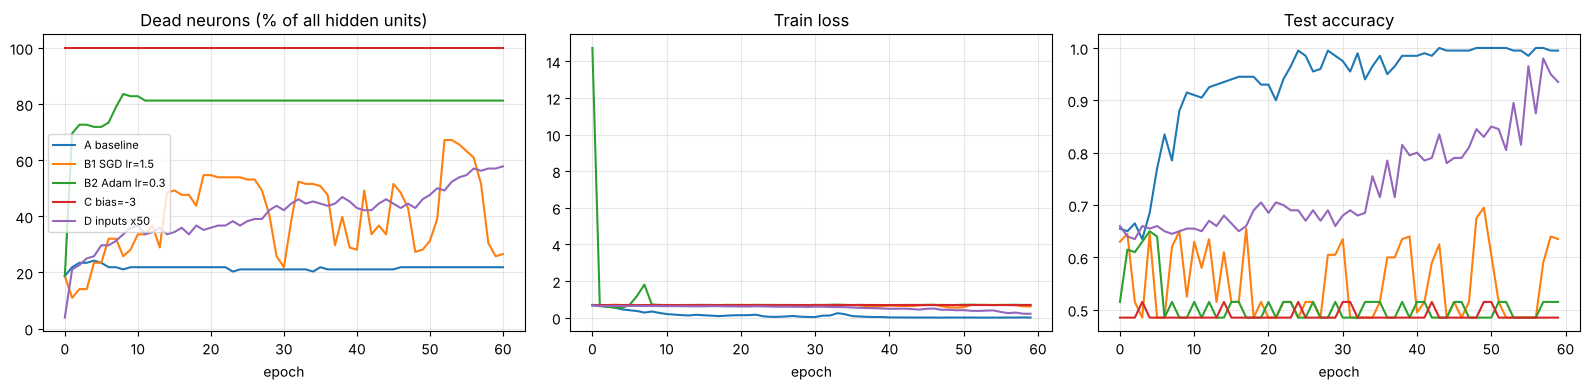

In [12]:
runs = {
    "A baseline": hist_a,
    "B1 SGD lr=1.5": hist_b1,
    "B2 Adam lr=0.3": hist_b2,
    "C bias=-3": hist_c,
    "D inputs x50": hist_d,
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, h in runs.items():
    axes[0].plot([100 * np.mean(d) for d in h["dead"]], label=name)
    axes[1].plot(h["train_loss"], label=name)
    axes[2].plot(h["test_acc"], label=name)
axes[0].set_title("Dead neurons (% of all hidden units)"); axes[0].set_xlabel("epoch")
axes[1].set_title("Train loss"); axes[1].set_xlabel("epoch")
axes[2].set_title("Test accuracy"); axes[2].set_xlabel("epoch")
for a in axes: a.grid(alpha=0.3)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

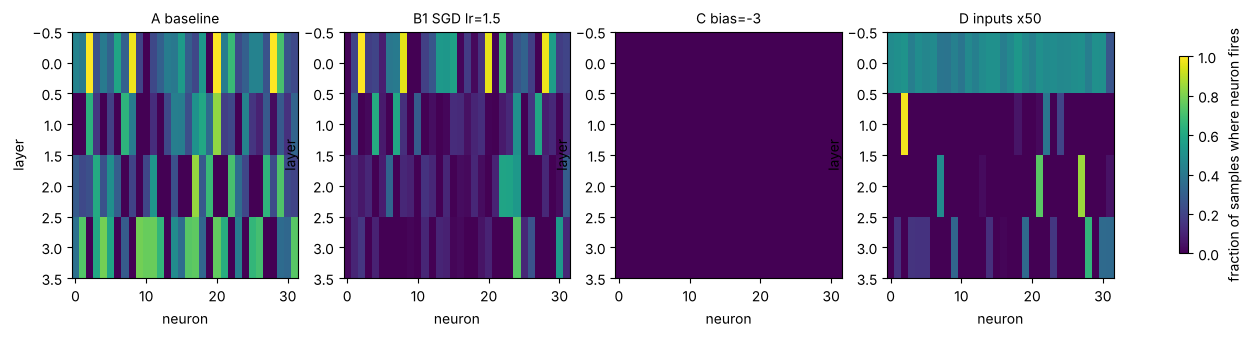

In [13]:
def plot_firing_heatmap(models_and_data, titles):
    fig, axes = plt.subplots(1, len(models_and_data), figsize=(4.2 * len(models_and_data), 3.2))
    axes = np.atleast_1d(axes)
    for ax, (m, Xd), t in zip(axes, models_and_data, titles):
        rates = np.stack(neuron_stats(m, Xd))          # [layers, hidden]
        im = ax.imshow(rates, vmin=0, vmax=1, cmap="viridis", aspect="auto")
        ax.set_title(t, fontsize=10); ax.set_xlabel("neuron"); ax.set_ylabel("layer")
    fig.colorbar(im, ax=axes, shrink=0.8, label="fraction of samples where neuron fires")
    plt.show()

plot_firing_heatmap(
    [(model_a, X_train), (model_b1, X_train), (model_c, X_train), (model_d, X_train * 50)],
    ["A baseline", "B1 SGD lr=1.5", "C bias=-3", "D inputs x50"],
)

Dark-purple cells (rate = 0) are dead neurons: these units contribute nothing, so the network behaves like a *much narrower* one than you paid for.

## 11. Dead neurons really are frozen

Let's prove it. Take a trained model with dead units, remember their weights, train 20 more epochs, and see if they moved.

In [14]:
def frozen_check(model, extra_epochs=20, lr=1e-2, optimizer_name="sgd"):
    model = copy.deepcopy(model)
    stats = neuron_stats(model, X_train)
    dead_idx = [np.where(s == 0)[0] for s in stats]
    before = [lin.weight.detach().clone() for lin in model.linears]
    opt = (torch.optim.Adam if optimizer_name == "adam" else torch.optim.SGD)(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    for _ in range(extra_epochs):
        train_one_epoch(model, train_loader, opt, loss_fn)
    for i, (lin, idx) in enumerate(zip(model.linears, dead_idx)):
        if len(idx):
            delta = (lin.weight.detach()[idx] - before[i][idx]).abs().max().item()
            print(f"layer {i}: {len(idx):2d} dead neurons | max weight change over {extra_epochs} epochs = {delta:.2e}")
    new_dead = dead_fraction(model, X_train)
    print("dead fraction per layer after:", [f"{d:.2f}" for d in new_dead])

print("Model C (bad bias init), more SGD training:")
frozen_check(model_c)

Model C (bad bias init), more SGD training:


layer 0: 32 dead neurons | max weight change over 20 epochs = 0.00e+00
layer 1: 32 dead neurons | max weight change over 20 epochs = 0.00e+00
layer 2: 32 dead neurons | max weight change over 20 epochs = 0.00e+00
layer 3: 32 dead neurons | max weight change over 20 epochs = 0.00e+00
dead fraction per layer after: ['1.00', '1.00', '1.00', '1.00']


The weights of dead units don't change at all: **dead means permanently dead** (with SGD; Adam/weight decay can still drift weights slightly because of momentum and decay terms, but there is no gradient signal pulling them back).

## 12. The fixes

Now we hold the optimiser fixed at a **moderately aggressive** setting (Adam, `lr=0.03`) and change one design choice at a time. We average over 3 random seeds because dead-neuron counts are noisy.

**A note on "dead" for non-ReLU activations.** Our detector counts a neuron as *inactive* if its pre-activation is $\le 0$ on every training sample. For ReLU that means truly dead (zero gradient). For Leaky ReLU / ELU / GELU an inactive neuron still has a small non-zero gradient, so it is *recoverable*. That's exactly why these activations help, even when the inactive count isn't zero.

| Fix | Why it helps |
|---|---|
| Lower the learning rate | Smaller steps don't fling neurons across the zero boundary |
| Kaiming (He) init | Keeps pre-activation variance stable so neurons *start* in a healthy region (fixes bad-init death, not LR-driven death) |
| Leaky ReLU / GELU / ELU | Non-zero gradient for $z<0$, so a neuron can recover |
| BatchNorm | Re-centres/scales pre-activations every batch, so they rarely sit entirely below 0 |
| Standardise inputs | Prevents huge pre-activations from the start |

In [15]:
HIGH = dict(optimizer_name="adam", lr=0.03)

experiments = {
    "ReLU (broken)":          dict(activation=nn.ReLU, **HIGH),
    "LeakyReLU":              dict(activation=lambda: nn.LeakyReLU(0.05), **HIGH),
    "ELU":                    dict(activation=nn.ELU, **HIGH),
    "GELU":                   dict(activation=nn.GELU, **HIGH),
    "ReLU + BatchNorm":       dict(activation=nn.ReLU, batchnorm=True, **HIGH),
    "ReLU + Kaiming init":    dict(activation=nn.ReLU, init="kaiming", **HIGH),
    "ReLU + lr/10 (0.003)":   dict(activation=nn.ReLU, optimizer_name="adam", lr=0.003),
}

SEEDS = [0, 1, 2]
results, fix_models, fix_hists = [], {}, {}
for name, cfg in experiments.items():
    accs, deads = [], []
    for sd in SEEDS:
        m_, h_ = run_experiment(name, verbose=False, seed=sd, **cfg)
        accs.append(h_["test_acc"][-1]); deads.append(100 * np.mean(h_["dead"][-1]))
        if sd == SEEDS[0]:
            fix_models[name], fix_hists[name] = m_, h_       # keep seed-0 run for plots
    results.append({"name": name, "test_acc": float(np.mean(accs)), "acc_min": float(np.min(accs)),
                    "dead_pct": float(np.mean(deads))})
    print(f"{name:24s} | test acc {np.mean(accs):.3f} (worst seed {np.min(accs):.3f}) | inactive {np.mean(deads):5.1f}%")

ReLU (broken)            | test acc 0.913 (worst seed 0.865) | inactive  55.2%


LeakyReLU                | test acc 0.983 (worst seed 0.965) | inactive  17.4%


ELU                      | test acc 0.863 (worst seed 0.690) | inactive  28.1%


GELU                     | test acc 0.985 (worst seed 0.980) | inactive   6.8%


ReLU + BatchNorm         | test acc 0.960 (worst seed 0.950) | inactive   6.0%


ReLU + Kaiming init      | test acc 0.992 (worst seed 0.985) | inactive  44.5%


ReLU + lr/10 (0.003)     | test acc 0.993 (worst seed 0.990) | inactive  18.0%


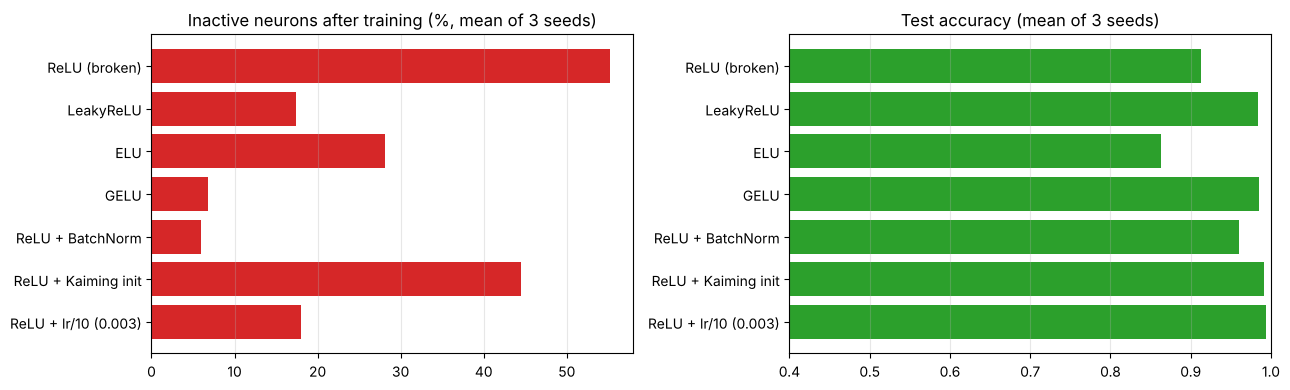

In [16]:
names = [r["name"] for r in results]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].barh(names, [r["dead_pct"] for r in results], color="tab:red")
axes[0].set_title("Inactive neurons after training (%, mean of 3 seeds)"); axes[0].invert_yaxis()
axes[1].barh(names, [r["test_acc"] for r in results], color="tab:green")
axes[1].set_xlim(0.4, 1.0); axes[1].set_title("Test accuracy (mean of 3 seeds)"); axes[1].invert_yaxis()
for a in axes: a.grid(alpha=0.3, axis="x")
plt.tight_layout(); plt.show()

### What does a dead network look like in input space?

Decision boundaries for the broken ReLU model versus a fixed one.

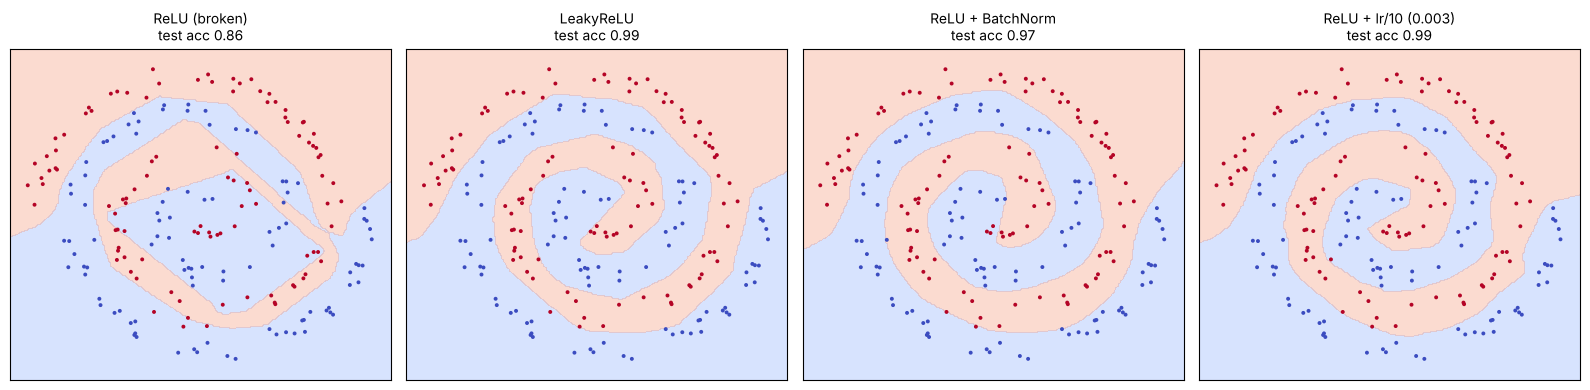

In [17]:
def plot_boundary(ax, model, title):
    model.eval()
    gx, gy = np.meshgrid(np.linspace(-2.2, 2.2, 250), np.linspace(-2.2, 2.2, 250))
    grid = torch.tensor(np.c_[gx.ravel(), gy.ravel()], dtype=torch.float32).to(device)
    with torch.no_grad():
        pred = model(grid).argmax(1).cpu().numpy().reshape(gx.shape)
    ax.contourf(gx, gy, pred, alpha=0.35, cmap="coolwarm", levels=1)
    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap="coolwarm", s=8, edgecolor="none")
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])

to_show = ["ReLU (broken)", "LeakyReLU", "ReLU + BatchNorm", "ReLU + lr/10 (0.003)"]
fig, axes = plt.subplots(1, len(to_show), figsize=(4 * len(to_show), 4))
for ax, nm in zip(axes, to_show):
    acc = fix_hists[nm]["test_acc"][-1]
    plot_boundary(ax, fix_models[nm], f"{nm}\ntest acc {acc:.2f}")
plt.tight_layout(); plt.show()

## 13. Practical monitoring tip

Don't wait until the loss is stuck. Log the dead fraction each epoch (as we did) or per N steps, and alert when it grows. In real projects you'd write the `neuron_stats` numbers to TensorBoard / W&B.

A rule of thumb: **if more than ~20-30% of a layer is dead, you're losing capacity.** Look at your learning rate, initialisation and input scaling first, then consider a Leaky ReLU / GELU family activation.

## 14. Exercises

1. **Width vs. death.** Re-run Experiment B1 with `hidden=128`. Does a wider net have a lower or higher *fraction* of dead neurons? Does accuracy still suffer?
2. **LeakyReLU slope.** Sweep the negative slope in `[0.0, 0.01, 0.05, 0.2]` under the `HIGH` setting. Plot dead % vs. accuracy.
3. **Depth.** Set `depth=10`. Dead neurons compound with depth, so how does the dead fraction per layer change from layer 0 to layer 9?
4. **Revive a dead neuron.** After training model C, re-initialise only the dead neurons' weights and biases with Kaiming init, then continue training. Does accuracy improve?
5. **Adam vs SGD.** Run `frozen_check` with `optimizer_name="adam"`. Does Adam move weights of dead units? Why or why not (hint: look at its update rule)?
6. **Real data.** Replace the spirals with FashionMNIST and watch dead neurons in a 3-layer MLP at LR 0.5 vs 0.01.

## 15. Key takeaways

- A ReLU neuron dies when its pre-activation is $\le 0$ on **all** inputs; the gradient is then exactly 0 and it cannot recover.
- Triggers: **high learning rate**, **bad init / negative biases**, **unscaled inputs**.
- You can **detect** it with a forward pre-hook counting how often $z>0$.
- Fixes: lower LR, **standardised inputs**, **BatchNorm**, and **Leaky ReLU / GELU**. Kaiming init helps when the problem is a bad *start*, but doesn't stop a too-high LR from killing neurons later.
- Dead neurons silently shrink your effective model size, so monitor them.